# Etapa 4 — Aprendizado Probabilístico: MLE, MAP, Naive Bayes e EM

**Pergunta prática (a mesma da Etapa 1):** dado o perfil e os sintomas de um paciente com dengue notificado, ele será hospitalizado?

**Dados:** Sinan/Dengue 2026 (`DENGBR26.csv`), Portal de Dados Abertos do SUS.

**Atributos:** exatamente os 6 atributos finais da Etapa 1 (`regiao`, `LEUCOPENIA`, `faixa_etaria`, `VOMITO`, `CEFALEIA`, `HIPERTENSA`), com o mesmo balanceamento 50/50 e a mesma divisão treino/teste (seed 42). Os conjuntos são reconstruídos pela função `treino_teste_etapa1` do `utils1e2.py` do repositório, que **não foi alterado**.

Antes de rodar, envie para `/content` os arquivos `DENGBR26.csv` e `utils1e2.py`. Depois, rode as células em ordem (Ambiente de execução → Executar tudo).

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import roc_auc_score, log_loss

# Do repositório: o mesmo arquivo usado nas Etapas 1 e 2 (sem alterações)
from utils1e2 import treino_teste_etapa1, ATRIBUTOS, arvore, acuracia, cv_id3

SEED = 42
np.random.seed(SEED)
CAMINHO_CSV = "/content/DENGBR26.csv"
ALPHA = 1.0   # pseudo-contagem de Laplace = estimativa MAP com prior Beta(2,2) / Dirichlet(2,...,2)

print("atributos (os mesmos da Etapa 1):", ATRIBUTOS)

atributos (os mesmos da Etapa 1): ['regiao', 'LEUCOPENIA', 'faixa_etaria', 'VOMITO', 'CEFALEIA', 'HIPERTENSA']


## 1. Funções (tudo do zero)

As funções estão separadas por assunto. Todas usam apenas `numpy`; o scikit-learn aparece só para conferência (seção 5) e para as métricas AUC e log-loss.

### 1.1 MLE e MAP para o parâmetro θ de uma Bernoulli

Seja $y_1,\dots,y_n \in \{0,1\}$ (1 = hospitalizado) e $k = \sum y_i$.

* **MLE:** maximiza $P(\text{dados}\mid\theta) = \theta^k(1-\theta)^{n-k}$, o que dá $\hat\theta_{MLE} = k/n$.
* **MAP com prior Beta(a, b):** a posteriori é $\text{Beta}(k+a,\, n-k+b)$, cuja moda é $\hat\theta_{MAP} = \dfrac{k+a-1}{n+a+b-2}$. Com **Beta(2,2)** isso vira $(k+1)/(n+2)$, que é a suavização de Laplace (somar 1 a cada contagem).

In [4]:
def bernoulli_mle(y):
    """theta_MLE = k / n (fração de sucessos)."""
    y = np.asarray(y)
    return y.sum() / len(y)


def bernoulli_map(y, a=2, b=2):
    """theta_MAP com prior Beta(a, b) = moda da posteriori Beta(k+a, n-k+b).
    Com Beta(2,2): (k + 1) / (n + 2)."""
    y = np.asarray(y)
    k, n = y.sum(), len(y)
    return (k + a - 1) / (n + a + b - 2)


def curvas_beta(k, n, a=2, b=2, pontos=2001):
    """Verossimilhança, prior e posteriori numa grade de theta (normalizadas para área 1)."""
    g = np.linspace(1e-4, 1 - 1e-4, pontos)
    passo = g[1] - g[0]
    log_lik = k * np.log(g) + (n - k) * np.log(1 - g)
    log_pri = (a - 1) * np.log(g) + (b - 1) * np.log(1 - g)

    def normaliza(lp):
        d = np.exp(lp - lp.max())
        return d / (d.sum() * passo)

    return g, normaliza(log_lik), normaliza(log_pri), normaliza(log_lik + log_pri)

### 1.2 Codificação dos atributos

Os atributos categóricos (texto) viram inteiros 0, 1, 2, ... para que as contagens possam ser feitas com `numpy`. O vocabulário vem **só do treino**; um valor que não apareceu no treino recebe -1 e é ignorado na previsão (o mesmo cuidado que a função `prever` do ID3 tem com valores nunca vistos).

In [5]:
def codificar(tr, te, atributos):
    """Retorna X_treino, X_teste (matrizes de inteiros) e o vocabulário de cada atributo."""
    vocab = {a: sorted(tr[a].unique()) for a in atributos}

    def cod(df):
        return np.column_stack([
            df[a].map({v: i for i, v in enumerate(vocab[a])}).fillna(-1).astype(int).to_numpy()
            for a in atributos])

    return cod(tr), cod(te), vocab


def logsumexp(L):
    """log(sum(exp(L))) por linha, sem estouro numérico."""
    m = L.max(axis=1, keepdims=True)
    return (m + np.log(np.exp(L - m).sum(axis=1, keepdims=True)))[:, 0]

### 1.3 Naive Bayes do zero

Modelo da AIMA (eq. 12.20): $P(C, x_1,\dots,x_6) = P(C)\prod_j P(x_j \mid C)$.

* **Treino:** cada tabela $P(x_j = v \mid C = c)$ é estimada por contagem. Com `alpha = 0` é o **MLE** (frequência relativa); com `alpha = 1` é o **MAP** com prior Dirichlet(2), isto é, Laplace: $\dfrac{\text{cont}(v, c) + 1}{n_c + |V_j|}$.
* **Previsão:** $P(C \mid x) = \alpha\, P(C)\prod_j P(x_j\mid C)$ (eq. 12.21). As contas são feitas em log para não dar *underflow*, e a normalização (o α) é feita no fim.

In [6]:
def nb_treinar(X, y, cards, alpha=ALPHA):
    """prior[c] = P(C=c);  theta[j][c, v] = P(x_j = v | C = c)."""
    prior = np.array([np.mean(y == c) for c in (0, 1)])
    theta = []
    for j, m in enumerate(cards):
        t = np.zeros((2, m))
        for c in (0, 1):
            cont = np.bincount(X[y == c, j], minlength=m)
            t[c] = (cont + alpha) / (cont.sum() + alpha * m)
        theta.append(t)
    return {"tipo": "nb", "prior": prior, "theta": theta}


def nb_log_conjunta(modelo, X):
    """Matriz (N x 2) com log P(C=c, x) = log P(c) + soma_j log P(x_j | c)."""
    with np.errstate(divide="ignore"):             # alpha = 0 pode gerar log(0) = -inf
        L = np.tile(np.log(modelo["prior"]), (len(X), 1))
        for j, t in enumerate(modelo["theta"]):
            ok = X[:, j] >= 0                      # ignora valor nunca visto no treino
            L[ok] += np.log(t[:, X[ok, j]]).T
    return L


def prob_hosp(L):
    """P(alvo = 1 | x) normalizando log P(c, x) (o alpha da eq. 12.21)."""
    with np.errstate(invalid="ignore"):
        m = L.max(axis=1, keepdims=True)
        e = np.exp(L - m)
        p = e[:, 1] / e.sum(axis=1)
    # se P(x | c) = 0 para as duas classes (só acontece no MLE), não há como decidir: 0,5
    return np.where(np.isfinite(m[:, 0]), p, 0.5)

### 1.4 EM com variável oculta Z (Naive Bayes + EM)

Introduzimos uma variável oculta $Z \in \{1,\dots,K\}$ (K = 2 ou 3) **dentro de cada classe**: os pacientes hospitalizados (e os não hospitalizados) podem vir de K "perfis" não observados. O modelo fica

$$P(C, x) = P(C)\sum_{k=1}^{K} P(Z=k\mid C)\prod_j P(x_j \mid Z=k, C).$$

Com K = 1 ele é exatamente o Naive Bayes da seção 1.3. Com K > 1 ele deixa de exigir que os atributos sejam independentes dado a classe (só exige isso dado a classe **e** o perfil Z), o que pode capturar interações como "região × leucopenia" que o NB puro ignora.

Como Z nunca é observado, os parâmetros são aprendidos com **EM**, separadamente em cada classe (o pseudocódigo do enunciado, trocando a gaussiana por tabelas categóricas):

* **E-step:** responsabilidade $r_{nk} = P(Z=k \mid x_n) \propto P(Z=k)\prod_j P(x_{nj}\mid Z=k)$, normalizada por exemplo.
* **M-step:** $N_k = \sum_n r_{nk}$; $P(Z=k) = N_k / N$; $P(x_j = v \mid Z=k) = \dfrac{\sum_n r_{nk}[x_{nj}=v] + \alpha}{N_k + \alpha |V_j|}$ (contagens **esperadas** com a mesma suavização MAP do NB).
* **Convergência:** para quando o ganho do objetivo por exemplo fica abaixo de `tol`.

A inicialização é aleatória (tabelas sorteadas de uma Dirichlet), então o EM é rodado `n_init` vezes com sementes diferentes e fica a melhor solução. O histórico guarda a **log-verossimilhança** $\sum_n \log P(x_n)$ e o **objetivo MAP** (log-verossimilhança + log-prior das tabelas), que o EM garante não diminuir.

In [7]:
def log_componentes(X, pi, theta):
    """Matriz (N x K) com log[ P(Z=k) * prod_j P(x_j | Z=k) ]."""
    L = np.tile(np.log(pi), (len(X), 1))
    for j, t in enumerate(theta):
        ok = X[:, j] >= 0
        L[ok] += np.log(t[:, X[ok, j]]).T
    return L


def em_mistura(X, cards, K, alpha=ALPHA, max_iter=300, tol=1e-5, seed=SEED):
    """EM para uma mistura de K componentes categóricos (exemplos de UMA classe)."""
    rng = np.random.default_rng(seed)
    N = len(X)
    pi = np.full(K, 1.0 / K)
    theta = [rng.dirichlet(np.ones(m), size=K) for m in cards]   # inicialização aleatória
    hist_ll, hist_obj = [], []

    for it in range(max_iter):
        # ---- E-step: responsabilidades r[n, k] = P(Z = k | x_n)
        L = log_componentes(X, pi, theta)
        log_px = logsumexp(L)                    # log P(x_n)
        r = np.exp(L - log_px[:, None])          # normaliza cada linha

        hist_ll.append(log_px.sum())
        hist_obj.append(log_px.sum() + alpha * sum(np.log(t).sum() for t in theta))
        if it > 0 and abs(hist_obj[-1] - hist_obj[-2]) / N < tol:
            break

        # ---- M-step: reestima P(Z) e P(x_j | Z) com contagens esperadas
        Nk = r.sum(axis=0)
        pi = Nk / N
        theta = []
        for j, m in enumerate(cards):
            cont = np.stack([r[X[:, j] == v].sum(axis=0) for v in range(m)], axis=1)  # K x m
            theta.append((cont + alpha) / (cont.sum(axis=1, keepdims=True) + alpha * m))

    return {"pi": pi, "theta": theta, "hist_ll": hist_ll, "hist_obj": hist_obj,
            "iteracoes": len(hist_ll)}


def nbem_treinar(X, y, cards, K, alpha=ALPHA, n_init=5, **kw):
    """Um EM por classe (melhor de n_init inicializações). prior[c] = P(C=c)."""
    prior = np.array([np.mean(y == c) for c in (0, 1)])
    comps = []
    for c in (0, 1):
        rodadas = [em_mistura(X[y == c], cards, K, alpha, seed=SEED + s, **kw) for s in range(n_init)]
        comps.append(max(rodadas, key=lambda m: m["hist_obj"][-1]))
    return {"tipo": "em", "K": K, "prior": prior, "comps": comps}


def nbem_log_conjunta(modelo, X):
    """Matriz (N x 2): log P(C=c, x) = log P(c) + log soma_k P(Z=k|c) prod_j P(x_j | k, c)."""
    return np.column_stack([
        np.log(modelo["prior"][c]) + logsumexp(log_componentes(X, comp["pi"], comp["theta"]))
        for c, comp in enumerate(modelo["comps"])])

### 1.5 Avaliação

`treinar` e `log_conjunta` escolhem o modelo pelo K (K = 1 → Naive Bayes puro; K ≥ 2 → NB + EM). `cv_modelo` faz a validação cruzada 5-fold estratificada com a mesma semente da Etapa 1, recodificando os atributos em cada fold (o vocabulário vem só da parte de treino do fold).

Além da acurácia (métrica do enunciado e da Etapa 1), reportamos a **AUC** e o **log-loss**, porque as probabilidades deste modelo serão usadas nas Etapas 5 e 6, e o log-loss mede justamente a qualidade dessas probabilidades (menor é melhor).

In [8]:
def treinar(X, y, cards, K):
    return nb_treinar(X, y, cards) if K == 1 else nbem_treinar(X, y, cards, K)


def log_conjunta(modelo, X):
    return nb_log_conjunta(modelo, X) if modelo["tipo"] == "nb" else nbem_log_conjunta(modelo, X)


def metricas(y, p):
    return {"acuracia": np.mean((p >= 0.5).astype(int) == y),
            "auc": roc_auc_score(y, p),
            "log_loss": log_loss(y, np.clip(p, 1e-12, 1 - 1e-12))}


def cv_modelo(dados, atributos, K, k=5, seed=SEED):
    """Métricas por fold (validação cruzada estratificada) do NB (K=1) ou NB + EM (K>=2)."""
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    dados = dados.reset_index(drop=True)
    y = dados["alvo"].to_numpy()
    res = []
    for tr, va in skf.split(dados, y):
        Xa, Xb, vocab = codificar(dados.iloc[tr], dados.iloc[va], atributos)
        modelo = treinar(Xa, y[tr], [len(vocab[a]) for a in atributos], K)
        res.append(metricas(y[va], prob_hosp(log_conjunta(modelo, Xb))))
    return res


def resumo_cv(res):
    return {m: np.mean([r[m] for r in res]) for m in ("acuracia", "auc", "log_loss")}

## 2. Carga dos dados (mesmo treino/teste da Etapa 1)

`treino_teste_etapa1` repete a preparação da Etapa 1: alvo `HOSPITALIZ` (1 = hospitalizou, 2 = não; nulo, 9 e 0 descartados), `faixa_etaria` e `regiao` derivadas, *undersampling* 50/50 e divisão 80/20 estratificada com seed 42. A tabela região × alvo abaixo deve ser idêntica à da seção 6 da Etapa 1 (centro-oeste 7623/5390, nordeste 4848/9544, ...).

Para o MLE/MAP da seção 3 também guardamos o alvo na **prevalência natural** (sem balancear), porque é nele que θ = P(hospitalização) tem significado epidemiológico.

In [9]:
treino, teste, info = treino_teste_etapa1(CAMINHO_CSV)
print(f"registros no arquivo: {info['registros']} | com desfecho válido: {info['validos']} | balanceado: {info['balanceado']}")
print("treino:", treino.shape, "| teste:", teste.shape)
print("proporção de hospitalizados no treino:", treino["alvo"].mean())
print("\nconferência com a Etapa 1 (região x alvo no treino):")
print(pd.crosstab(treino["regiao"], treino["alvo"]).rename(columns={0: "nao", 1: "sim"}))

# alvo na prevalência natural (sem balancear), para MLE e MAP
hosp = pd.read_csv(CAMINHO_CSV, usecols=["HOSPITALIZ"], encoding="latin-1", low_memory=False)["HOSPITALIZ"]
y_nat = (hosp[hosp.isin([1, 2])] == 1).astype(int).to_numpy()
print("\nalvo natural:", len(y_nat), "casos válidos,", y_nat.sum(), "hospitalizações")

# codificação (vocabulário do treino)
Xtr, Xte, vocab = codificar(treino, teste, ATRIBUTOS)
cards = [len(vocab[a]) for a in ATRIBUTOS]
ytr, yte = treino["alvo"].to_numpy(), teste["alvo"].to_numpy()
print("\nvalores de cada atributo (1.0 = sim, 2.0 = não):")
for a in ATRIBUTOS:
    print(f"  {a:13s} {vocab[a]}")

registros no arquivo: 470451 | com desfecho válido: 346765 | balanceado: 59380
treino: (47504, 7) | teste: (11876, 7)
proporção de hospitalizados no treino: 0.5

conferência com a Etapa 1 (região x alvo no treino):
alvo           nao   sim
regiao                  
centro-oeste  7623  5390
nordeste      4848  9544
norte         1471  2383
sudeste       9025  5645
sul            785   790

alvo natural: 346765 casos válidos, 29690 hospitalizações

valores de cada atributo (1.0 = sim, 2.0 = não):
  regiao        ['centro-oeste', 'nordeste', 'norte', 'sudeste', 'sul']
  LEUCOPENIA    ['1.0', '2.0']
  faixa_etaria  ['adulto', 'crianca', 'idoso']
  VOMITO        ['1.0', '2.0']
  CEFALEIA      ['1.0', '2.0']
  HIPERTENSA    ['1.0', '2.0']


## 3. MLE e MAP do parâmetro θ = P(hospitalização)

Primeiro na base inteira (prevalência natural). Depois um experimento: sorteamos 500 amostras pequenas de tamanho n e comparamos o erro de cada estimador em relação ao θ da base inteira (tratado como o "valor verdadeiro"). Além da Beta(2,2) pedida no enunciado (centrada em 0,5), testamos uma prior **informada** Beta(2,12), cuja moda é 1/12 ≈ 0,083, próxima da taxa de hospitalização conhecida para dengue.

In [10]:
theta_mle = bernoulli_mle(y_nat)
theta_map = bernoulli_map(y_nat, 2, 2)
print(f"n = {len(y_nat)}  k = {y_nat.sum()}")
print(f"theta_MLE           = {theta_mle:.6f}")
print(f"theta_MAP Beta(2,2) = {theta_map:.6f}")
print(f"diferença           = {abs(theta_mle - theta_map):.2e}  (com n grande a prior não pesa)")

rng = np.random.default_rng(SEED)
linhas = []
for n in [5, 10, 20, 50, 100, 500, 2000]:
    e_mle, e_map, e_inf, k0 = [], [], [], 0
    for _ in range(500):
        s = y_nat[rng.choice(len(y_nat), n, replace=False)]
        e_mle.append(abs(bernoulli_mle(s) - theta_mle))
        e_map.append(abs(bernoulli_map(s) - theta_mle))
        e_inf.append(abs(bernoulli_map(s, 2, 12) - theta_mle))
        k0 += int(s.sum() == 0)
    linhas.append({"n": n, "erro medio MLE": np.mean(e_mle), "erro medio MAP Beta(2,2)": np.mean(e_map),
                   "erro medio MAP Beta(2,12)": np.mean(e_inf),
                   "% amostras com k=0 (MLE = 0)": 100 * k0 / 500})
erros = pd.DataFrame(linhas)
print()
print(erros.round(4).to_string(index=False))

n = 346765  k = 29690
theta_MLE           = 0.085620
theta_MAP Beta(2,2) = 0.085622
diferença           = 2.39e-06  (com n grande a prior não pesa)

   n  erro medio MLE  erro medio MAP Beta(2,2)  erro medio MAP Beta(2,12)  % amostras com k=0 (MLE = 0)
   5          0.1127                    0.1221                     0.0336                          62.8
  10          0.0711                    0.0742                     0.0321                          39.2
  20          0.0519                    0.0556                     0.0323                          13.2
  50          0.0331                    0.0354                     0.0267                           2.0
 100          0.0221                    0.0222                     0.0197                           0.0
 500          0.0100                    0.0100                     0.0097                           0.0
2000          0.0050                    0.0050                     0.0050                           0.0


Exemplo de uma amostra pequena (n = 20) em que **ninguém** foi hospitalizado (k = 0): o MLE conclui θ = 0 ("dengue nunca hospitaliza"), enquanto o MAP com Beta(2,2) mantém um valor pequeno, mas positivo.

amostra n=20, k=0: MLE = 0.0000 | MAP = 0.0455 | base inteira = 0.0856


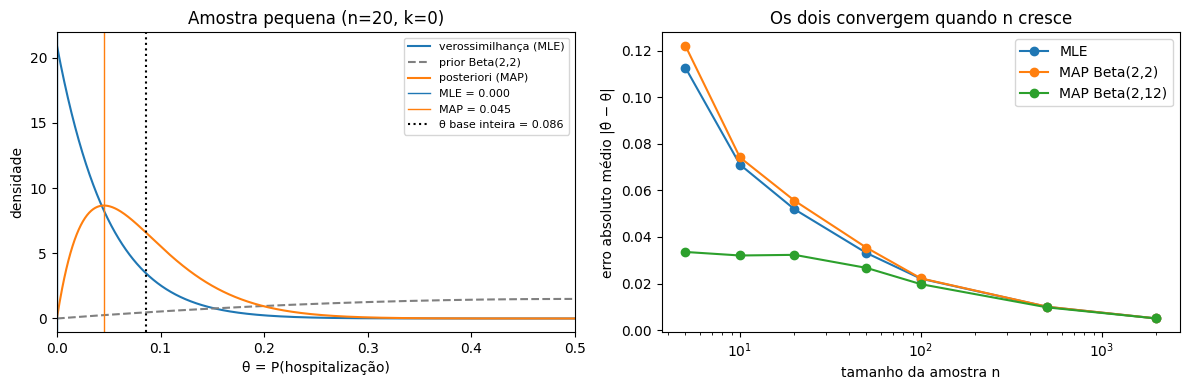

In [11]:
n_ex, k_ex = 20, 0
g, lik, pri, post = curvas_beta(k_ex, n_ex, 2, 2)
mle_ex, map_ex = k_ex / n_ex, (k_ex + 1) / (n_ex + 2)
print(f"amostra n={n_ex}, k={k_ex}: MLE = {mle_ex:.4f} | MAP = {map_ex:.4f} | base inteira = {theta_mle:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(g, lik, label="verossimilhança (MLE)")
ax[0].plot(g, pri, "--", color="gray", label="prior Beta(2,2)")
ax[0].plot(g, post, label="posteriori (MAP)")
ax[0].axvline(mle_ex, color="C0", lw=1, label=f"MLE = {mle_ex:.3f}")
ax[0].axvline(map_ex, color="C1", lw=1, label=f"MAP = {map_ex:.3f}")
ax[0].axvline(theta_mle, color="k", ls=":", label=f"θ base inteira = {theta_mle:.3f}")
ax[0].set_xlim(0, 0.5); ax[0].set_xlabel("θ = P(hospitalização)"); ax[0].set_ylabel("densidade")
ax[0].set_title(f"Amostra pequena (n={n_ex}, k={k_ex})"); ax[0].legend(fontsize=8)

ax[1].plot(erros["n"], erros["erro medio MLE"], "o-", label="MLE")
ax[1].plot(erros["n"], erros["erro medio MAP Beta(2,2)"], "o-", label="MAP Beta(2,2)")
ax[1].plot(erros["n"], erros["erro medio MAP Beta(2,12)"], "o-", label="MAP Beta(2,12)")
ax[1].set_xscale("log"); ax[1].set_xlabel("tamanho da amostra n")
ax[1].set_ylabel("erro absoluto médio |θ̂ − θ|"); ax[1].set_title("Os dois convergem quando n cresce")
ax[1].legend()
fig.tight_layout(); fig.savefig("etapa4_mle_map.png", dpi=150); plt.show()

## 4. MLE vs MAP dentro do Naive Bayes (o problema da frequência zero)

No Naive Bayes, cada $P(x_j \mid C)$ é uma Bernoulli/categórica estimada por contagem. Com o MLE, um valor que não apareceu numa classe recebe probabilidade 0 e **anula todo o produto** da eq. 12.21 (a nota 8 do capítulo 12 da AIMA alerta para isso). Treinamos o NB com amostras de treino de vários tamanhos (100 sorteios por tamanho), com `alpha = 0` (MLE) e `alpha = 1` (MAP), e avaliamos sempre no mesmo conjunto de teste. O log-loss usa probabilidades limitadas a [1e-12, 1 − 1e-12]; sem esse limite, uma única probabilidade 0 para a classe verdadeira daria log-loss infinito.

 n treino  acurácia NB-MLE  acurácia NB-MAP  log-loss NB-MLE  log-loss NB-MAP  % teste com P(x|c)=0 (MLE)
       20           0.5897           0.5798           4.3414           0.7549                     35.5837
       50           0.6168           0.6154           1.7627           0.6920                     11.7358
      100           0.6325           0.6325           0.9762           0.6575                      3.5737
      200           0.6502           0.6502           0.6890           0.6340                      0.6564
      500           0.6607           0.6610           0.6212           0.6201                      0.0000
     2000           0.6673           0.6673           0.6132           0.6131                      0.0000
    47504           0.6689           0.6689           0.6105           0.6105                      0.0000


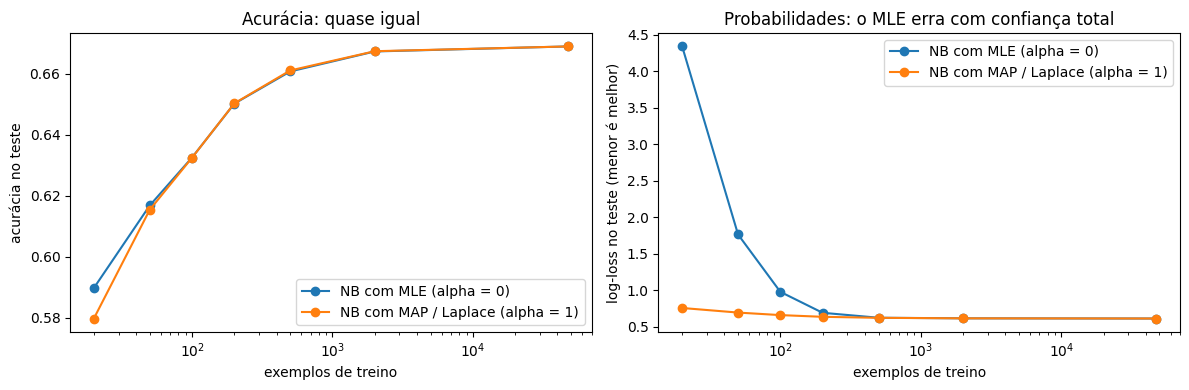

In [12]:
rng = np.random.default_rng(SEED)
linhas = []
for n in [20, 50, 100, 200, 500, 2000, len(treino)]:
    acc = {0.0: [], 1.0: []}
    ll = {0.0: [], 1.0: []}
    zeros = []
    for rep in range(100 if n < len(treino) else 1):
        idx = rng.choice(len(treino), n, replace=False)
        sub = treino.iloc[idx]
        if sub["alvo"].nunique() < 2:
            continue
        Xa, Xb, voc = codificar(sub, teste, ATRIBUTOS)
        cd = [len(voc[a]) for a in ATRIBUTOS]
        for alpha in (0.0, 1.0):
            m = nb_treinar(Xa, sub["alvo"].to_numpy(), cd, alpha=alpha)
            L = nb_log_conjunta(m, Xb)
            p = prob_hosp(L)
            acc[alpha].append(np.mean((p >= 0.5).astype(int) == yte))
            ll[alpha].append(log_loss(yte, np.clip(p, 1e-12, 1 - 1e-12)))
            if alpha == 0.0:
                zeros.append(np.mean(np.isinf(L).any(axis=1)))   # algum P(x | c) = 0
    linhas.append({"n treino": n, "acurácia NB-MLE": np.mean(acc[0.0]), "acurácia NB-MAP": np.mean(acc[1.0]),
                   "log-loss NB-MLE": np.mean(ll[0.0]), "log-loss NB-MAP": np.mean(ll[1.0]),
                   "% teste com P(x|c)=0 (MLE)": 100 * np.mean(zeros)})
nb_n = pd.DataFrame(linhas)
print(nb_n.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for col, titulo, i in [("acurácia", "acurácia no teste", 0), ("log-loss", "log-loss no teste (menor é melhor)", 1)]:
    ax[i].plot(nb_n["n treino"], nb_n[f"{col} NB-MLE"], "o-", label="NB com MLE (alpha = 0)")
    ax[i].plot(nb_n["n treino"], nb_n[f"{col} NB-MAP"], "o-", label="NB com MAP / Laplace (alpha = 1)")
    ax[i].set_xscale("log"); ax[i].set_xlabel("exemplos de treino"); ax[i].set_ylabel(titulo); ax[i].legend()
ax[0].set_title("Acurácia: quase igual")
ax[1].set_title("Probabilidades: o MLE erra com confiança total")
fig.tight_layout(); fig.savefig("etapa4_nb_mle_map.png", dpi=150); plt.show()

## 5. Naive Bayes do zero: treino, teste e conferência com o scikit-learn

Treino com o conjunto de treino inteiro da Etapa 1 e `alpha = 1` (MAP). Primeiro as tabelas aprendidas (são as CPTs de uma rede Bayesiana com a classe como único pai de cada atributo).

In [ ]:
nb = nb_treinar(Xtr, ytr, cards)
print("P(alvo):  nao =", nb["prior"][0], "| sim =", nb["prior"][1], "\n")

for j, a in enumerate(ATRIBUTOS):
    tab = pd.DataFrame(nb["theta"][j].T, index=vocab[a], columns=["P(v | nao)", "P(v | sim)"])
    tab["razao sim/nao"] = tab["P(v | sim)"] / tab["P(v | nao)"]
    print(f"--- {a}")
    print(tab.round(4).to_string(), "\n")

P(alvo):  nao = 0.5 | sim = 0.5 

--- regiao
              P(v | nao)  P(v | sim)  razao sim/nao
centro-oeste      0.3209      0.2269         0.7071
nordeste          0.2041      0.4018         1.9684
norte             0.0620      0.1003         1.6196
sudeste           0.3799      0.2377         0.6255
sul               0.0331      0.0333         1.0064 

--- LEUCOPENIA
     P(v | nao)  P(v | sim)  razao sim/nao
1.0      0.0371      0.1513         4.0737
2.0      0.9629      0.8487         0.8815 

--- faixa_etaria
         P(v | nao)  P(v | sim)  razao sim/nao
adulto       0.7706      0.6346         0.8235
crianca      0.1409      0.1960         1.3914
idoso        0.0885      0.1694         1.9130 

--- VOMITO
     P(v | nao)  P(v | sim)  razao sim/nao
1.0      0.2798      0.4173         1.4916
2.0      0.7202      0.5827         0.8090 

--- CEFALEIA
     P(v | nao)  P(v | sim)  razao sim/nao
1.0      0.8027      0.6805         0.8478
2.0      0.1973      0.3195         1.6192 

--

Exemplo de cálculo à mão (eq. 12.21) para o primeiro paciente do teste: multiplica-se a prior pelas 6 probabilidades condicionais em cada classe e normaliza-se.

In [ ]:
pac = teste.iloc[0]
x0 = Xte[0]
print("paciente:", dict(pac[ATRIBUTOS]), "| alvo real:", pac["alvo"], "\n")

prod = nb["prior"].copy()
print(f"{'fator':28s} {'nao':>9s} {'sim':>9s}")
print(f"{'P(alvo)':28s} {nb['prior'][0]:9.4f} {nb['prior'][1]:9.4f}")
for j, a in enumerate(ATRIBUTOS):
    f = nb["theta"][j][:, x0[j]]
    prod = prod * f
    print(f"{'P(' + a + '=' + str(pac[a]) + ' | c)':28s} {f[0]:9.4f} {f[1]:9.4f}")
print(f"{'produto (não normalizado)':28s} {prod[0]:9.6f} {prod[1]:9.6f}")
post = prod / prod.sum()
print(f"{'P(c | x) (normalizado)':28s} {post[0]:9.4f} {post[1]:9.4f}")
print("\nconferência com prob_hosp:", prob_hosp(nb_log_conjunta(nb, Xte[:1]))[0])

paciente: {'regiao': 'centro-oeste', 'LEUCOPENIA': '2.0', 'faixa_etaria': 'adulto', 'VOMITO': '1.0', 'CEFALEIA': '1.0', 'HIPERTENSA': '2.0'} | alvo real: 0 

fator                              nao       sim
P(alvo)                         0.5000    0.5000
P(regiao=centro-oeste | c)      0.3209    0.2269
P(LEUCOPENIA=2.0 | c)           0.9629    0.8487
P(faixa_etaria=adulto | c)      0.7706    0.6346
P(VOMITO=1.0 | c)               0.2798    0.4173
P(CEFALEIA=1.0 | c)             0.8027    0.6805
P(HIPERTENSA=2.0 | c)           0.9278    0.8606
produto (não normalizado)     0.024806  0.014935
P(c | x) (normalizado)          0.6242    0.3758

conferência com prob_hosp: 0.37582066791580765


Desempenho e comparação com `CategoricalNB` do scikit-learn (mesma suavização `alpha = 1`). As probabilidades devem coincidir até o erro de arredondamento.

In [ ]:
p_nb = prob_hosp(nb_log_conjunta(nb, Xte))
p_nb_tr = prob_hosp(nb_log_conjunta(nb, Xtr))

sk = CategoricalNB(alpha=1.0, min_categories=cards).fit(Xtr, ytr)
p_sk = sk.predict_proba(Xte)[:, 1]

print(f"NB do zero  treino: {np.mean((p_nb_tr >= .5) == ytr):.4f} | teste: {np.mean((p_nb >= .5) == yte):.4f}")
print(f"sklearn     treino: {sk.score(Xtr, ytr):.4f} | teste: {sk.score(Xte, yte):.4f}")
print(f"maior diferença entre as probabilidades: {np.abs(p_nb - p_sk).max():.2e}")
print("\nmétricas no teste (NB do zero):", {k: round(float(v), 4) for k, v in metricas(yte, p_nb).items()})

NB do zero  treino: 0.6623 | teste: 0.6689
sklearn     treino: 0.6623 | teste: 0.6689
maior diferença entre as probabilidades: 9.99e-16

métricas no teste (NB do zero): {'acuracia': 0.6689, 'auc': 0.7251, 'log_loss': 0.6105}


## 6. EM com variável oculta Z: convergência e log-verossimilhança

Ajustamos o NB + EM no treino com K = 2 e K = 3 componentes. Para cada classe mostramos o número de iterações, a log-verossimilhança inicial e final e se ela foi **monotonicamente crescente** em todas as iterações. A linha tracejada é a log-verossimilhança do NB puro (K = 1) na mesma classe: o EM com K ≥ 2 deve ficar acima dela, porque o NB é um caso particular do modelo com Z.

No gráfico, a iteração 1 (parâmetros sorteados, log-verossimilhança muito baixa) foi omitida para não achatar a escala; o valor dela está na coluna "logL inicial" da tabela.

In [ ]:
modelos_em = {K: nbem_treinar(Xtr, ytr, cards, K) for K in (2, 3)}

# log-verossimilhança do NB puro (K = 1) em cada classe, para referência
ll_nb_classe = []
for c in (0, 1):
    Lc = np.zeros((ytr == c).sum())
    for j, t in enumerate(nb["theta"]):
        Lc += np.log(t[c, Xtr[ytr == c, j]])
    ll_nb_classe.append(Lc.sum())

nome_classe = {0: "nao hospitalizado", 1: "hospitalizado"}
linhas = []
for K, m in modelos_em.items():
    for c in (0, 1):
        h = np.array(m["comps"][c]["hist_ll"])
        o = np.array(m["comps"][c]["hist_obj"])
        h2 = h[1:]                               # a partir da iteração 2 (após o 1º M-step)
        n99 = int(np.argmax(h2 - h2[0] >= 0.99 * (h2[-1] - h2[0]))) + 2
        linhas.append({"K": K, "classe": nome_classe[c], "iteracoes": len(h),
                       "it. p/ 99% do ganho (desde it. 2)": n99,
                       "logL inicial": round(h[0], 1), "logL final": round(h[-1], 1),
                       "logL NB puro": round(ll_nb_classe[c], 1),
                       "logL monotônica": bool(np.all(np.diff(h) >= -1e-6)),
                       "objetivo MAP monotônico": bool(np.all(np.diff(o) >= -1e-6))})
conv = pd.DataFrame(linhas)
print(conv.to_string(index=False))

 K            classe  iteracoes  it. p/ 99% do ganho (desde it. 2)  logL inicial  logL final  logL NB puro  logL monotônica  objetivo MAP monotônico
 2 nao hospitalizado        129                                116     -173344.9    -83175.6      -84093.1             True                     True
 2     hospitalizado         96                                 75     -149212.6   -102665.7     -105259.3             True                     True
 3 nao hospitalizado         92                                 61     -129131.6    -82660.1      -84093.1             True                     True
 3     hospitalizado         46                                 30     -185542.2   -101782.8     -105259.3             True                     True


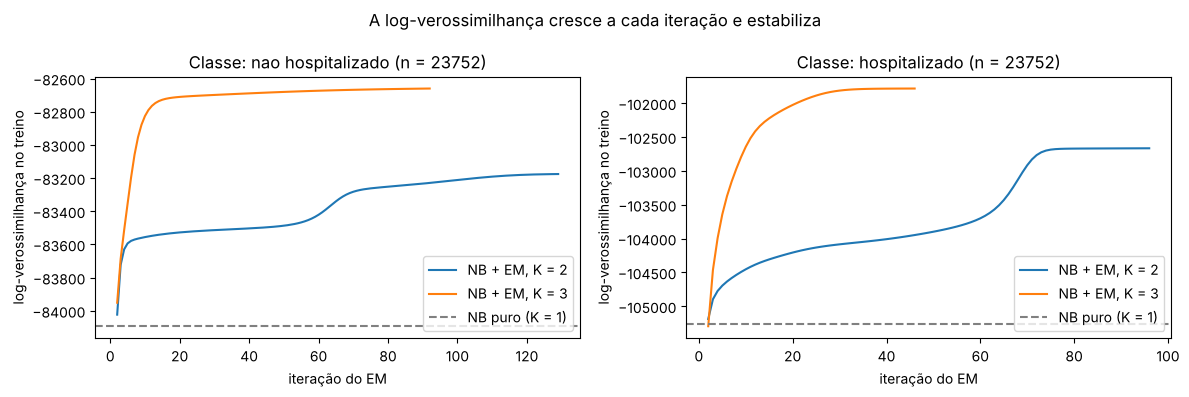

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c in (0, 1):
    for K, cor in [(2, "C0"), (3, "C1")]:
        h = modelos_em[K]["comps"][c]["hist_ll"]
        ax[c].plot(np.arange(2, len(h) + 1), h[1:], "-", color=cor, label=f"NB + EM, K = {K}")
    ax[c].axhline(ll_nb_classe[c], color="gray", ls="--", label="NB puro (K = 1)")
    ax[c].set_title(f"Classe: {nome_classe[c]} (n = {(ytr == c).sum()})")
    ax[c].set_xlabel("iteração do EM"); ax[c].set_ylabel("log-verossimilhança no treino")
    ax[c].legend()
fig.suptitle("A log-verossimilhança cresce a cada iteração e estabiliza")
fig.tight_layout(); fig.savefig("etapa4_em_loglik.png", dpi=150); plt.show()

## 7. Escolha do número de componentes K (5-fold dentro do treino)

Como na escolha da profundidade da Etapa 1, o K é escolhido por validação cruzada **só no treino**, sem olhar o teste. K = 1 é o NB puro (referência). Entre K = 2 e K = 3 fica o de maior acurácia média.

In [ ]:
cv_treino = {}
for K in (1, 2, 3):
    cv_treino[K] = resumo_cv(cv_modelo(treino, ATRIBUTOS, K))
    r = cv_treino[K]
    nome = "NB puro" if K == 1 else f"NB + EM K={K}"
    print(f"{nome:14s} 5-fold no treino: acurácia={r['acuracia']:.4f}  AUC={r['auc']:.4f}  log-loss={r['log_loss']:.4f}")

K_OTIMO = max((2, 3), key=lambda K: cv_treino[K]["acuracia"])
print("\nK escolhido para o NB + EM:", K_OTIMO)

NB puro        5-fold no treino: acurácia=0.6624  AUC=0.7219  log-loss=0.6138


NB + EM K=2    5-fold no treino: acurácia=0.6623  AUC=0.7234  log-loss=0.6128


NB + EM K=3    5-fold no treino: acurácia=0.6652  AUC=0.7244  log-loss=0.6119

K escolhido para o NB + EM: 3


## 8. Comparação final: Naive Bayes puro vs. Naive Bayes + EM (e a árvore da Etapa 1)

Mesmo protocolo da Etapa 1: acurácia de treino e de teste com os modelos ajustados no treino, e validação 5-fold no conjunto balanceado inteiro (treino + teste). A árvore ID3 sem poda da Etapa 1 é recalculada com as funções do `utils1e2.py` como referência.

In [ ]:
dados_cv = pd.concat([treino, teste]).reset_index(drop=True)
linhas, folds = [], {}

for K in (1, 2, 3):
    m = nb if K == 1 else modelos_em[K]
    p_tr = prob_hosp(log_conjunta(m, Xtr))
    p_te = prob_hosp(log_conjunta(m, Xte))
    cv = cv_modelo(dados_cv, ATRIBUTOS, K)
    nome = "Naive Bayes puro" if K == 1 else f"NB + EM (K={K})"
    folds[nome] = [round(float(r["acuracia"]), 4) for r in cv]
    linhas.append({"modelo": nome,
                   "treino": np.mean((p_tr >= .5) == ytr),
                   "teste": np.mean((p_te >= .5) == yte),
                   "5-fold (media)": resumo_cv(cv)["acuracia"],
                   "AUC teste": roc_auc_score(yte, p_te),
                   "log-loss teste": log_loss(yte, p_te)})

# referência: ID3 sem poda da Etapa 1
id3 = arvore(treino, ATRIBUTOS)
cv3 = cv_id3(dados_cv, ATRIBUTOS)
folds["ID3 (Etapa 1)"] = [round(float(a), 4) for a in cv3]
linhas.append({"modelo": "ID3 sem poda (Etapa 1)", "treino": acuracia(id3, treino),
               "teste": acuracia(id3, teste), "5-fold (media)": np.mean(cv3),
               "AUC teste": np.nan, "log-loss teste": np.nan})

resultado = pd.DataFrame(linhas)
print(resultado.round(4).to_string(index=False))
print()
for nome, f in folds.items():
    print(f"5-fold {nome:18s}: {f}")

                modelo  treino  teste  5-fold (media)  AUC teste  log-loss teste
      Naive Bayes puro  0.6623 0.6689          0.6636     0.7251          0.6105
         NB + EM (K=2)  0.6620 0.6688          0.6638     0.7259          0.6097
         NB + EM (K=3)  0.6660 0.6644          0.6657     0.7269          0.6092
ID3 sem poda (Etapa 1)  0.6670 0.6632          0.6627        NaN             NaN

5-fold Naive Bayes puro  : [0.6623, 0.673, 0.6598, 0.6612, 0.6618]
5-fold NB + EM (K=2)     : [0.6616, 0.6745, 0.6591, 0.6628, 0.6612]
5-fold NB + EM (K=3)     : [0.665, 0.6682, 0.6632, 0.6637, 0.6684]
5-fold ID3 (Etapa 1)     : [0.6651, 0.6676, 0.6564, 0.6592, 0.6653]


## 9. O que a variável oculta Z aprendeu

Para o K escolhido, cada linha é um "perfil" latente dentro de uma classe: o peso $P(Z=k \mid C)$ e a probabilidade de algumas características nesse perfil. É isso que o NB puro não consegue representar: dentro de uma mesma classe, grupos de pacientes com combinações diferentes de região e sintomas.

In [ ]:
def p_valor(theta_j, vocab_j, valor):
    return theta_j[:, vocab_j.index(valor)]

m = modelos_em[K_OTIMO]
linhas = []
for c in (0, 1):
    comp = m["comps"][c]
    th = dict(zip(ATRIBUTOS, comp["theta"]))
    for k in range(K_OTIMO):
        linha = {"classe": nome_classe[c], "Z": k + 1, "P(Z|classe)": comp["pi"][k]}
        for r in vocab["regiao"]:
            linha[f"P({r})"] = p_valor(th["regiao"], vocab["regiao"], r)[k]
        for a in ["LEUCOPENIA", "VOMITO", "CEFALEIA", "HIPERTENSA"]:
            linha[f"P({a}=sim)"] = p_valor(th[a], vocab[a], "1.0")[k]
        linha["P(idoso)"] = p_valor(th["faixa_etaria"], vocab["faixa_etaria"], "idoso")[k]
        linha["P(crianca)"] = p_valor(th["faixa_etaria"], vocab["faixa_etaria"], "crianca")[k]
        linhas.append(linha)
perfis = pd.DataFrame(linhas)
pd.set_option("display.width", 250)
tab_perfis = perfis.set_index(["classe", "Z"]).T
tab_perfis.columns = [f"{'nao' if c.startswith('nao') else 'sim'} Z{z}" for c, z in tab_perfis.columns]
print(tab_perfis.round(3).to_string())

                   nao Z1  nao Z2  nao Z3  sim Z1  sim Z2  sim Z3
P(Z|classe)         0.118   0.677   0.205   0.234   0.412   0.354
P(centro-oeste)     0.338   0.320   0.314   0.295   0.182   0.234
P(nordeste)         0.150   0.201   0.247   0.250   0.454   0.441
P(norte)            0.043   0.059   0.082   0.063   0.108   0.116
P(sudeste)          0.407   0.389   0.333   0.332   0.232   0.181
P(sul)              0.062   0.031   0.025   0.060   0.023   0.028
P(LEUCOPENIA=sim)   0.054   0.032   0.045   0.166   0.131   0.165
P(VOMITO=sim)       0.224   0.265   0.360   0.346   0.437   0.441
P(CEFALEIA=sim)     0.756   0.878   0.581   0.591   0.460   0.997
P(HIPERTENSA=sim)   0.389   0.038   0.002   0.505   0.004   0.056
P(idoso)            0.626   0.018   0.012   0.689   0.006   0.017
P(crianca)          0.002   0.020   0.621   0.004   0.470   0.004


## 10. Salvar as probabilidades (para reuso nas Etapas 5 e 6)

As probabilidades de hospitalização de cada paciente do teste, pelo NB puro e pelo NB + EM, ficam em `etapa4_probabilidades_teste.csv`, junto com os atributos e o alvo. A Etapa 6 pode compará-las com as da rede Bayesiana e usar qualquer uma como entrada do sistema fuzzy.

In [ ]:
saida = teste[ATRIBUTOS + ["alvo"]].copy()
saida["p_nb"] = p_nb
saida[f"p_nb_em_k{K_OTIMO}"] = prob_hosp(log_conjunta(modelos_em[K_OTIMO], Xte))
saida.to_csv("etapa4_probabilidades_teste.csv", index=False)
print("salvo: etapa4_probabilidades_teste.csv", saida.shape)
print(saida.head().round(4).to_string(index=False))

salvo: etapa4_probabilidades_teste.csv (11876, 9)
      regiao LEUCOPENIA faixa_etaria VOMITO CEFALEIA HIPERTENSA  alvo   p_nb  p_nb_em_k3
centro-oeste        2.0       adulto    1.0      1.0        2.0     0 0.3758      0.4173
centro-oeste        2.0       adulto    2.0      1.0        2.0     0 0.2462      0.2566
centro-oeste        2.0       adulto    2.0      1.0        2.0     1 0.2462      0.2566
     sudeste        2.0       adulto    2.0      1.0        2.0     1 0.2241      0.2033
    nordeste        1.0      crianca    2.0      2.0        2.0     1 0.9313      0.9016
